# Online learning with delayed, partial and noisy labels

In the main results the online model receives the true label of every sample right after
predicting it. Here that assumption is relaxed in three ways:

- **Label delay**: the label of the sample seen at time t only reaches the model at
  time t + d. The prediction that is scored is still the one made at time t.
- **Label budget**: only a random fraction of the samples is ever labelled.
- **Label noise**: a fraction of the delivered labels is replaced by a wrong class, chosen
  at random from the failure types that have already appeared in the stream.

Every setting is run over ten seeds. The periodically retrained model of the main results
is included as a reference.

In [2]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import (PHASE_NAMES, load_dataset, make_training_set, make_phased_stream, make_arf,
                   train_river_model, run_stream, run_batch_retraining, rolling_accuracy,
                   recovery_time)

DATA_DIR = "data"
FIG_DIR = "figures"
SEED = 42
N_SEEDS = 10

LABEL_DELAYS = [0, 250, 1000, 2500]          # in samples
LABEL_FRACTIONS = [0.01, 0.05, 0.10]         # share of samples that get a label
LABEL_NOISE = [0.05, 0.10]                   # share of labels that are wrong

os.makedirs(FIG_DIR, exist_ok=True)

train_df, test_df = load_dataset(DATA_DIR)
X_train, y_train = make_training_set(train_df, seed=SEED)

## Run all settings

In [2]:
SETTINGS = ([("label delay", d, dict(label_delay=d)) for d in LABEL_DELAYS] +
            [("label fraction", f, dict(label_fraction=f)) for f in LABEL_FRACTIONS] +
            [("label noise", q, dict(label_noise=q)) for q in LABEL_NOISE])


def summarise(preds, y, starts):
    return {"errors": int((preds != y).sum()),
            "recovery after EDFA": recovery_time(y, preds, starts[1]),
            "recovery after NLI": recovery_time(y, preds, starts[2])}


rows = []
for seed in range(N_SEEDS):
    X_stream, y_stream, starts = make_phased_stream(test_df, seed=seed)
    arf = train_river_model(make_arf(seed), X_train, y_train)

    for setting, value, options in SETTINGS:
        preds, _ = run_stream(arf, X_stream, y_stream, seed=seed, **options)
        rows.append({"setting": setting, "value": value, "seed": seed,
                     **summarise(preds, y_stream, starts)})

    preds, _, _ = run_batch_retraining(X_train, y_train, X_stream, y_stream, starts[1:], seed)
    rows.append({"setting": "periodic retraining", "value": 5000, "seed": seed,
                 **summarise(preds, y_stream, starts)})
    print(f"seed {seed} done")

results = pd.DataFrame(rows)
results.to_csv("results_label_availability.csv", index=False)

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
seed 5 done
seed 6 done
seed 7 done
seed 8 done
seed 9 done


## Table 5: misclassifications and recovery time (mean ± std over seeds)

Recovery time is the number of samples after an onset until the error rate over the next
200 samples drops below 1%. "recovered" counts the seeds in which this happened within the
phase; the mean recovery time is taken over those seeds only.

In [3]:
def mean_std(values):
    values = pd.Series(values).dropna()
    return f"{values.mean():.0f} ± {values.std():.0f}" if len(values) else "-"


table = []
for (setting, value), group in results.groupby(["setting", "value"], sort=False):
    table.append({
        "setting": setting,
        "value": f"{value:g}",
        "errors": mean_std(group["errors"]),
        "recovery after EDFA": mean_std(group["recovery after EDFA"]),
        "recovered (EDFA)": f"{group['recovery after EDFA'].notna().sum()}/{len(group)}",
        "recovery after NLI": mean_std(group["recovery after NLI"]),
        "recovered (NLI)": f"{group['recovery after NLI'].notna().sum()}/{len(group)}",
    })
pd.DataFrame(table)

,setting,value,errors,recovery after EDFA,recovered (EDFA),recovery after NLI,recovered (NLI)
0,label delay,0,104 ± 13,254 ± 236,10/10,102 ± 118,10/10
1,label delay,250,248 ± 18,406 ± 126,10/10,314 ± 40,10/10
2,label delay,1000,675 ± 26,1210 ± 251,10/10,1072 ± 59,10/10
3,label delay,2500,1543 ± 37,2833 ± 262,10/10,2564 ± 46,10/10
4,label fraction,0.01,2879 ± 680,-,0/10,3143 ± 1307,6/10
5,label fraction,0.05,582 ± 86,1764 ± 429,10/10,286 ± 257,10/10
6,label fraction,0.1,415 ± 99,1469 ± 1261,10/10,288 ± 288,10/10
7,label noise,0.05,113 ± 16,272 ± 232,10/10,124 ± 104,10/10
8,label noise,0.1,112 ± 15,194 ± 92,10/10,127 ± 50,10/10
9,periodic retraining,5000,2944 ± 52,-,0/10,-,0/10


## Fig. 9: rolling accuracy with delayed labels and with a label budget (seed 42)

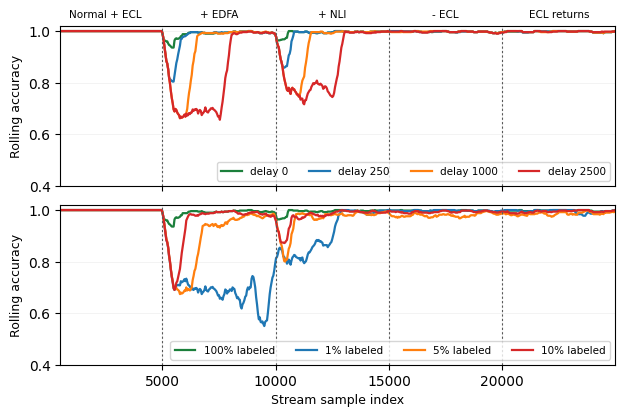

In [3]:
X_stream, y_stream, starts = make_phased_stream(test_df, seed=SEED)
arf = train_river_model(make_arf(SEED), X_train, y_train)

fig, (ax_delay, ax_budget) = plt.subplots(2, 1, figsize=(7.16, 4.4), sharex=True,
                                          gridspec_kw={"hspace": 0.12})
colors = ["#1b7f3b", "#1f77b4", "#ff7f0e", "#d62728"]

for d, color in zip(LABEL_DELAYS, colors):
    preds, _ = run_stream(arf, X_stream, y_stream, label_delay=d, seed=SEED)
    x, acc = rolling_accuracy(y_stream, preds)
    ax_delay.plot(x, acc, color=color, lw=1.6, label=f"delay {d}")

for f, color in zip([1.0] + LABEL_FRACTIONS, colors):
    preds, _ = run_stream(arf, X_stream, y_stream, label_fraction=f, seed=SEED)
    x, acc = rolling_accuracy(y_stream, preds)
    ax_budget.plot(x, acc, color=color, lw=1.6, label=f"{f:.0%} labeled")

edges = starts + [len(y_stream)]
for ax in (ax_delay, ax_budget):
    for start in starts[1:]:
        ax.axvline(start, color="0.35", ls=(0, (2, 2)), lw=0.8)
    ax.set_ylim(0.4, 1.02)
    ax.margins(x=0)
    ax.grid(alpha=0.2, lw=0.5)
    ax.set_ylabel("Rolling accuracy", fontsize=9)
    ax.legend(fontsize=7.5, ncol=4, loc="lower right")
for k, name in enumerate(PHASE_NAMES):
    ax_delay.text((edges[k] + edges[k + 1]) / 2, 1.04, name, ha="center", va="bottom",
                  fontsize=7.5, transform=ax_delay.get_xaxis_transform())
ax_budget.set_xlabel("Stream sample index", fontsize=9)
fig.savefig(f"{FIG_DIR}/label_availability.pdf", bbox_inches="tight")
plt.show()